<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week2_day4_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:

from google.colab import files
files.upload()



Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"deepti251","key":"4dec490a8a3c95e6f4eeee8747919fe1"}'}

In [25]:
!pip install kagglehub

import kagglehub

path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
print("Files saved in:", path)

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Files saved in: /kaggle/input/superstore-dataset-final


In [28]:
import os
print(os.listdir(path))

['Sample - Superstore.csv']


In [50]:
import pandas as pd

sample_store = pd.read_csv(os.path.join(path, "Sample - Superstore.csv"), encoding="latin1")
sample_store.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact, Dropdown, IntSlider
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

In [41]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
df.info()
df.describe()
df.isnull().sum()

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [46]:

df_with_row_index = df.set_index('Row ID')
display(df_with_row_index.head())


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
Row ID,,,,,,,,,,,,,,,,,,,,
1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [53]:
cols_to_check = [c for c in sample_store.columns if c != "Row ID"]

before = sample_store.shape
sample_store = sample_store.drop_duplicates(subset=cols_to_check)
print("Rows removed:", before[0] - sample_store.shape[0])



Rows removed: 1


In [55]:
before = sample_store.shape
sample_store = sample_store.loc[:, ~sample_store.T.duplicated()]
print("Columns removed:", before[1] - sample_store.shape[1])

Columns removed: 0


In [56]:
print("Final shape:", sample_store.shape)

Final shape: (9993, 21)


In [8]:
import pandas as pd
import os
import kagglehub

try:
    sample_store
except NameError:
    path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
    sample_store = pd.read_csv(os.path.join(path, "Sample - Superstore.csv"), encoding="latin1")

# Display the missing values count
print(sample_store.isnull().sum())

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [9]:
print(sample_store.isnull().sum().sum())


0


In [10]:
print((sample_store.isnull().mean() * 100).round(2))

Row ID           0.0
Order ID         0.0
Order Date       0.0
Ship Date        0.0
Ship Mode        0.0
Customer ID      0.0
Customer Name    0.0
Segment          0.0
Country          0.0
City             0.0
State            0.0
Postal Code      0.0
Region           0.0
Product ID       0.0
Category         0.0
Sub-Category     0.0
Product Name     0.0
Sales            0.0
Quantity         0.0
Discount         0.0
Profit           0.0
dtype: float64


In [13]:
date_columns = ['Order Date', 'Ship Date']

for col in date_columns:
    sample_store[col] = pd.to_datetime(sample_store[col])

In [14]:
print("Data types after conversion: date_columns")
print(sample_store[date_columns].dtypes)

Data types after conversion: date_columns
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [15]:
sample_store.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [16]:
profit_margin = (sample_store['Profit'] / sample_store['Sales']) * 100
sample_store.insert(6, 'Profit Margin', profit_margin)
sample_store.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Profit Margin,Customer Name,Segment,Country,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,16.00,Claire Gute,Consumer,United States,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,30.00,Claire Gute,Consumer,United States,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,47.00,Darrin Van Huff,Corporate,United States,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,-40.00,Sean O'Donnell,Consumer,United States,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,11.25,Sean O'Donnell,Consumer,United States,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [50]:
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

sample_store['Order Year'] = sample_store['Order Date'].dt.year
sample_store['Order Month'] = sample_store['Order Date'].dt.month
sample_store['Order Month-Year'] = sample_store['Order Date'].dt.to_period('M')

categories = ['All'] + list(sample_store['Category'].unique())

def plot_monthly_sales(category):
    plt.figure(figsize=(12, 6))

    if category == 'All':
        df_filtered = sample_store.groupby('Order Month-Year')['Sales'].sum().reset_index()
        plt.title('Monthly Sales Trend - All Categories', fontsize=16, fontweight='bold')
    else:
        df_filtered = sample_store[sample_store['Category'] == category].groupby('Order Month-Year')['Sales'].sum().reset_index()
        plt.title(f'Monthly Sales Trend - {category} Category', fontsize=16, fontweight='bold')

    df_filtered['Date'] = df_filtered['Order Month-Year'].dt.to_timestamp()

    # Plotting
    plt.plot(df_filtered['Date'], df_filtered['Sales'], marker='o', linewidth=2, color='#1f77b4')
    plt.xlabel('Date (Year-Month)', fontsize=12)
    plt.ylabel('Total Sales ($)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

interact(plot_monthly_sales, category=widgets.Dropdown(options=categories, value='All', description='Category:'))

interactive(children=(Dropdown(description='Category:', options=('All', 'Furniture', 'Office Supplies', 'Techn…

<function __main__.plot_monthly_sales(category)>

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
import pandas as pd
import os
import kagglehub
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

try:
    sample_store
except NameError:
    path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
    sample_store = pd.read_csv(os.path.join(path, "Sample - Superstore.csv"), encoding="latin1")

state_sales = sample_store.groupby('State')['Sales'].sum().sort_values(ascending=False).reset_index()

def plot_top_states(top_n=10):
    plt.figure(figsize=(12, max(6, top_n * 0.4)))

    top_states = state_sales.head(top_n).iloc[::-1]

    plt.barh(top_states['State'], top_states['Sales'], color='steelblue')
    plt.xlabel('Total Sales ($)', fontsize=12)
    plt.ylabel('State', fontsize=12)
    plt.title(f'Top {top_n} States by Sales', fontsize=14, fontweight='bold')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

top_n_slider = widgets.IntSlider(min=5, max=25, value=10, description='Top N States:')
interact(plot_top_states, top_n=top_n_slider);

interactive(children=(IntSlider(value=10, description='Top N States:', max=25, min=5), Output()), _dom_classes…

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets
import seaborn as sns

In [8]:
product_profits = sample_store.groupby('Product Name')['Profit'].sum().reset_index()
product_profits = product_profits.sort_values(by='Profit', ascending=False)

/tmp/ipykernel_822/3245269395.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


Key Insights:
• Most profitable product generates: $25,200
• Top 10 products contribute: $66,479 total profit
• Average profit per top product: $6,648


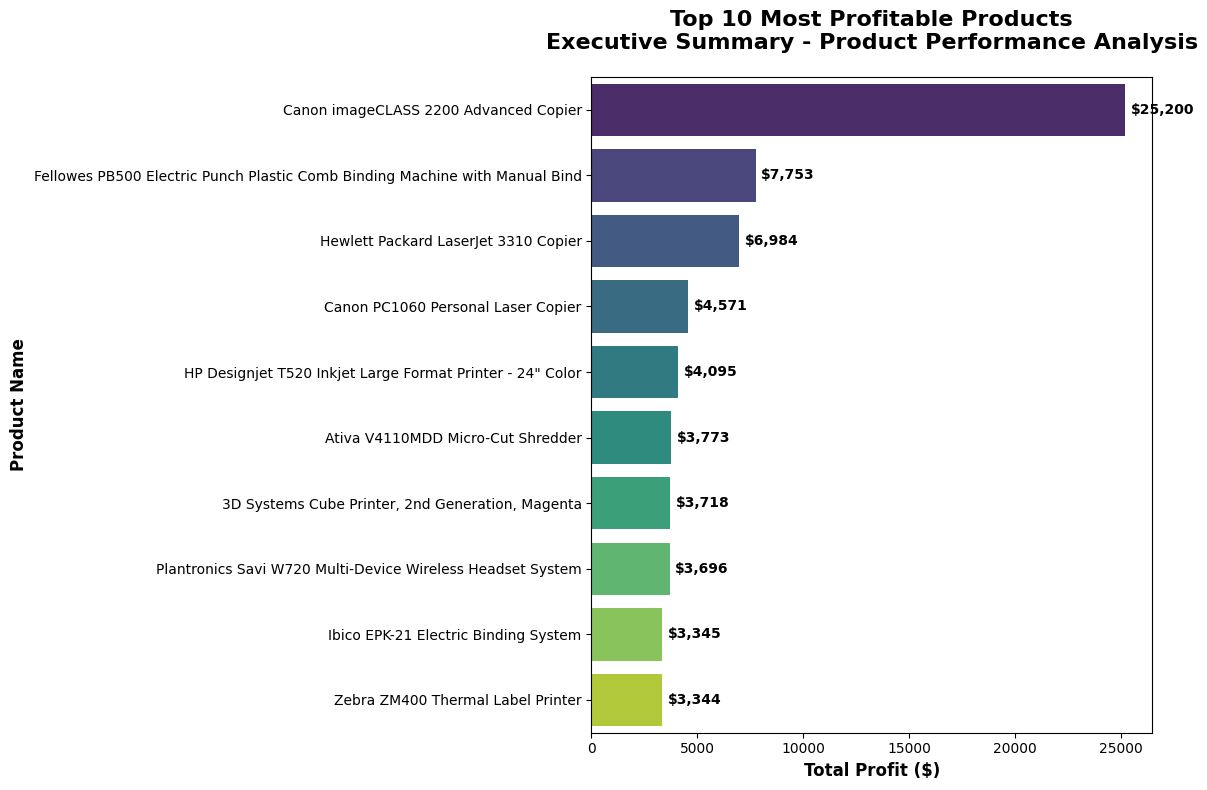

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

top_10_products = product_profits.head(10)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top_10_products,
    x='Profit',
    y='Product Name',
    palette='viridis',
    orient='h'
)

plt.title("Top 10 Most Profitable Products\nExecutive Summary - Product Performance Analysis", fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Total Profit ($)', fontsize=12, fontweight='bold')
plt.ylabel('Product Name', fontsize=12, fontweight='bold')

max_profit = top_10_products['Profit'].max()
for i, row in enumerate(top_10_products.itertuples()):
    profit = row.Profit
    ax.text(
        profit + (max_profit * 0.01),
        i,
        f'${profit:,.0f}',
        va='center',
        fontweight='bold',
        fontsize=10
    )

print("Key Insights:")
print(f"• Most profitable product generates: ${product_profits.iloc[0]['Profit']:,.0f}")
print(f"• Top 10 products contribute: ${top_10_products['Profit'].sum():,.0f} total profit")
print(f"• Average profit per top product: ${top_10_products['Profit'].mean():,.0f}")

plt.tight_layout()
plt.show()

Discount Analysis Insights:
• Transactions with >20% discount: 1,393
• Average profit for high discounts: $-97.18
• Percentage of high-discount sales with losses: 96.8%


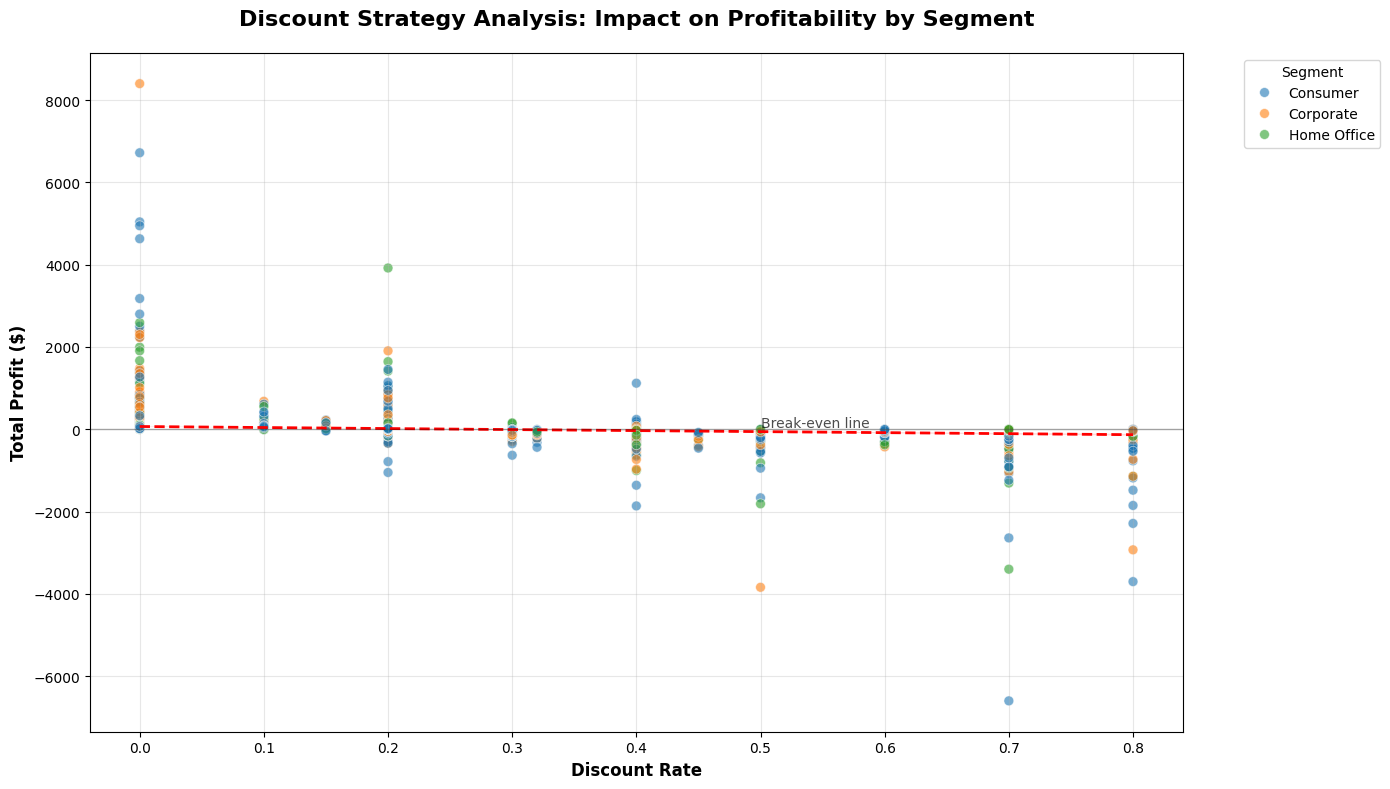

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os
import kagglehub
from ipywidgets import interact, widgets

try:
    sample_store
except NameError:
    path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
    sample_store = pd.read_csv(os.path.join(path, "Sample - Superstore.csv"), encoding="latin1")

state_sales = sample_store.groupby('State')['Sales'].sum().sort_values(ascending=False).reset_index()
plt.figure(figsize=(14, 8))

# Scatterplot
sns.scatterplot(data=sample_store, x='Discount', y='Profit', hue='Segment', alpha=0.6, s=50)

# Corrected the missing quote on 'linestyle'
sns.regplot(data=sample_store, x='Discount', y='Profit', scatter=False, color='red', line_kws={'linewidth': 2, 'linestyle': '--'})

plt.title('Discount Strategy Analysis: Impact on Profitability by Segment', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Discount Rate', fontsize=12, fontweight='bold')
plt.ylabel('Total Profit ($)', fontsize=12, fontweight='bold')
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
plt.text(0.5, 50, 'Break-even line', fontsize=10, alpha=0.7)

plt.grid(True, alpha=0.3)
plt.legend(title='Segment', bbox_to_anchor=(1.05, 1), loc='upper left')

print("Discount Analysis Insights:")
high_discount = sample_store[sample_store['Discount'] > 0.2]
print(f"• Transactions with >20% discount: {len(high_discount):,}")
print(f"• Average profit for high discounts: ${high_discount['Profit'].mean():.2f}")
print(f"• Percentage of high-discount sales with losses: {(high_discount['Profit'] < 0).mean()*100:.1f}%")

plt.tight_layout()
plt.show()

4. Methodology and Tooling Review: Matplotlib vs. Seaborn

In this project I used both libraries. Seaborn is built on top of Matplotlib, so they work well together, but each was better suited to different tasks.

Matplotlib
**What I used it for:** The monthly sales trend line chart with a category dropdown, and the "Top N States by Sales" horizontal bar chart with a slider. I also used it for custom touches such as the break-even line (`axhline`), the "Break-even line" text label, and the gridlines.

**Strengths**
- Full control over every part of the chart: figure size, titles, axis labels, tick rotation and gridlines.
- Works smoothly with `ipywidgets`, which let me build interactive charts that redraw when the user changes a value.
- Good for custom annotations and text placement.

**Weaknesses**
- It takes more lines of code to get a clean-looking chart. Each chart needed separate settings for titles, labels, grid and layout.
- The default styling is basic.

### Seaborn
**What I used it for:** The "Top 10 Most Profitable Products" bar chart, and the Discount vs. Profit analysis, which combined a scatter plot with a regression line (`regplot`).

**Strengths**
- Shorter code for statistical and category-based charts. One line of code gave me a scatter plot with automatic colours and a legend by segment.
- Built-in colour palettes (such as `viridis`) and clean default styling.
- Built-in statistical features, such as the regression line showing the trend between discount and profit.

**Weaknesses**
- Less flexible for fully custom layouts. For the labels on the bars and the break-even line, I still needed Matplotlib commands.
- It is not designed for interactive widgets.

### Speed
Both libraries were fast on this dataset . In the timing test, matplotlib did took more time and understanding.  for Seaborn, it was easier to plot for charts and graphs which took me less time

### Conclusion
I would use matplotlib when I need control or interactivity. I do think matplolib does has more feature available even though it takes time to get used to it. Seaborn when I want a quick, good-looking statistical chart. In this project the best results came from combining them: Seaborn to draw the chart, and Matplotlib to polish and annotate it.

In [17]:
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
import time
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sample_store['Order Date'] = pd.to_datetime(sample_store['Order Date'])
sample_store['Ship Date'] = pd.to_datetime(sample_store['Ship Date'])
sample_store['Order Year'] = sample_store['Order Date'].dt.year

start = time.time()
plt.figure(figsize=(8, 6))
plt.plot(sample_store.groupby('Order Year')['Sales'].sum())
plt.close()
matplotlib_time = time.time() - start

start = time.time()
plt.figure(figsize=(8, 6))
sns.lineplot(data=sample_store.groupby('Order Year')['Sales'].sum().reset_index(), x='Order Year', y='Sales')
plt.close()
seaborn_time = time.time() - start

print(f"• Matplotlib basic plot: {matplotlib_time:.4f} seconds")
print(f"• Seaborn equivalent: {seaborn_time:.4f} seconds")


• Matplotlib basic plot: 0.0198 seconds
• Seaborn equivalent: 0.0505 seconds


In [30]:
total_sales = sample_store['Sales'].sum()
total_profit = sample_store['Profit'].sum()
profit_margin = (total_profit / total_sales) * 100

# state_sales is sorted in descending order, so the top state is at index 0
top_state = state_sales.iloc[0]['State']
top_state_sales = state_sales.iloc[0]['Sales']

print(f"• Total Sales: ${total_sales:,.0f}")
print(f"• Total Profit: ${total_profit:,.0f}")
print(f"• Overall Profit Margin: {profit_margin:.1f}%")
print(f"• Top State by Sales: {top_state} with ${top_state_sales:,.0f} sales")
print()

print(f"🗺️ GEOGRAPHIC PERFORMANCE:")
print(f"• Top performing state: ({top_state_sales:,.0f})")
print(f"• Geographic concentration: Top 5 states = {(state_sales.head(5)['Sales'].sum()/total_sales)*100:.1f}% of sales")
print()


• Total Sales: $2,297,201
• Total Profit: $286,397
• Overall Profit Margin: 12.5%
• Top State by Sales: California with $457,688 sales

🗺️ GEOGRAPHIC PERFORMANCE:
• Top performing state: (457,688)
• Geographic concentration: Top 5 states = 52.0% of sales



In [31]:
top_category = sample_store.groupby('Category')['Sales'].sum().sort_values(ascending=False).index[0]
print(f"🏆 PRODUCT PERFORMANCE:")
print(f"• Leading category: {top_category}")
print(f"• Most profitable product: {product_profits.index[0]}")
print()

🏆 PRODUCT PERFORMANCE:
• Leading category: Technology
• Most profitable product: 404



In [33]:
high_discount_loss_rate = (sample_store[sample_store['Discount'] > 0.2]['Profit'] < 0).mean() * 100
max_discount_threshold = 0.2
print(f"💰 DISCOUNT STRATEGY INSIGHTS:")
print(f"• High discount risk: {high_discount_loss_rate:.1f}% of >20% discounts result in losses")
print(f"• Recommended max discount threshold: 20% to maintain profitability", 'max_discount_threshold')
print()

💰 DISCOUNT STRATEGY INSIGHTS:
• High discount risk: 96.8% of >20% discounts result in losses
• Recommended max discount threshold: 20% to maintain profitability max_discount_threshold



Using Colab cache for faster access to the 'superstore-dataset-final' dataset.


<Figure size 1600x1200 with 0 Axes>

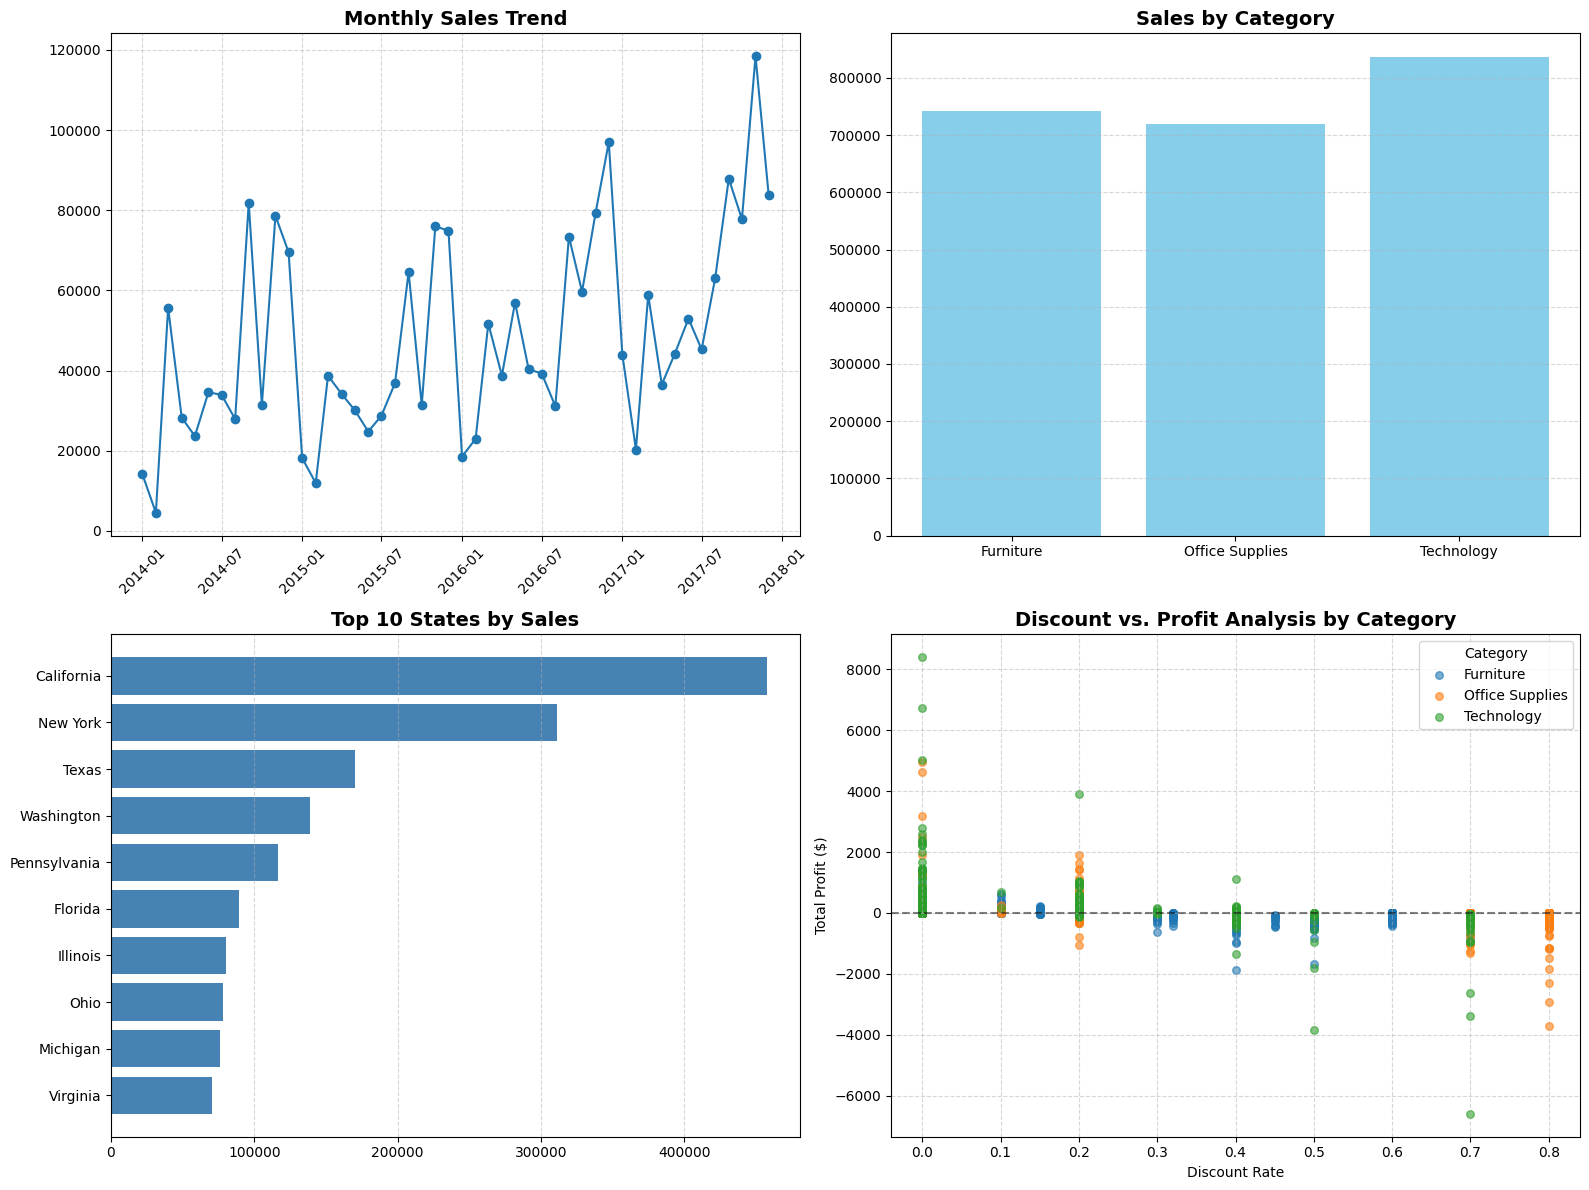

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import kagglehub

try:
    sample_store
except NameError:
    path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
    sample_store = pd.read_csv(os.path.join(path, "Sample - Superstore.csv"), encoding="latin1")
    sample_store['Order Date'] = pd.to_datetime(sample_store['Order Date'])
    sample_store['Order Month-Year'] = sample_store['Order Date'].dt.to_period('M')

def create_dashboard():
    plt.figure(figsize=(16, 12))
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    monthly_total = sample_store.groupby('Order Month-Year')['Sales'].sum()
    ax1.plot(monthly_total.index.to_timestamp(), monthly_total.values, marker='o', color='#1f77b4')
    ax1.set_title('Monthly Sales Trend', fontsize=14, fontweight='bold')
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # 2. Sales by Category
    category_sales = sample_store.groupby('Category')['Sales'].sum()
    ax2.bar(category_sales.index, category_sales.values, color='skyblue')
    ax2.set_title('Sales by Category', fontsize=14, fontweight='bold')
    ax2.grid(axis='y', linestyle='--', alpha=0.5)

    # 3. Top States by Sales
    state_sales = sample_store.groupby('State')['Sales'].sum().sort_values(ascending=False).head(10).iloc[::-1]
    ax3.barh(state_sales.index, state_sales.values, color='steelblue')
    ax3.set_title('Top 10 States by Sales', fontsize=14, fontweight='bold')
    ax3.grid(axis='x', linestyle='--', alpha=0.5)

    # 4. Discount vs. Profit Analysis by Category
    for category in sample_store['Category'].unique():
        cat_data = sample_store[sample_store['Category'] == category]
        ax4.scatter(cat_data['Discount'], cat_data['Profit'], label=category, alpha=0.6, s=30)

    ax4.set_title('Discount vs. Profit Analysis by Category', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Discount Rate')
    ax4.set_ylabel('Total Profit ($)')
    ax4.legend(title='Category')
    ax4.axhline(y=0, color='black', linestyle='--', alpha=0.5)
    ax4.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

create_dashboard()
